In [496]:
import pandas as pd
import numpy as np
import re, ast, unicodedata
import seaborn as sns
from scipy.stats import skew
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, RandomizedSearchCV, cross_validate, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder,MultiLabelBinarizer
from sklearn.impute import SimpleImputer

from sklearn.metrics import classification_report, ConfusionMatrixDisplay, confusion_matrix
from sklearn.metrics import roc_curve, roc_auc_score

# The Dataset
1. [New York Times Best Sellers](https://www.kaggle.com/datasets/dhruvildave/new-york-times-best-sellers) -> books put on the NYT BSL published from  **2010 to 2019**
2. [Top Goodreads Books Collection](https://www.kaggle.com/datasets/cristaliss/ultimate-book-collection-top-100-books-up-to-2023) -> **1980-2023**
3. [Kindle Books Dataset](https://www.kaggle.com/datasets/asaniczka/amazon-kindle-books-dataset-2023-130k-books) -> **1979 - 2023**

In [665]:
df_goodreads = pd.read_csv("C:\GitHub\A Bunch of Datasets\goodreads_top100_from1980to2023_final.csv")
df_nyt = pd.read_csv("bestsellers.csv")
df_kindle = pd.read_csv("kindle_data-v2.csv")

In [666]:
df_goodreads.drop(["Unnamed: 0", "series_release_number", "publisher", "language", "description", "publication_date", "num_reviews", "current_readers", "want_to_read", "url"], axis=1, inplace=True)
df_nyt.drop(["published_date", "list_name_encoded","isbn10", "description", "amazon_product_url", "weeks_on_list"], axis=1, inplace=True)
df_kindle.drop(["soldBy", "imgUrl", "productURL", "isKindleUnlimited", "isEditorsPick", "category_id", "reviews", "publishedDate"], axis=1, inplace=True)

In [667]:
print("\nGoodreads Columns:", df_goodreads.shape[0], "rows")
print("Columns:\n", df_goodreads.columns)

print("NYT Bestsellers:", df_nyt.shape[0], "rows")
print("Columns:\n",df_nyt.columns)

print("\nKindle Columns:", df_kindle.shape[0], "rows")
print("Columns:\n", df_kindle.columns) 


Goodreads Columns: 4400 rows
Columns:
 Index(['isbn', 'title', 'series_title', 'authors', 'num_pages', 'format',
       'genres', 'rating_score', 'num_ratings', 'price'],
      dtype='object')
NYT Bestsellers: 61430 rows
Columns:
 Index(['list_name', 'rank', 'isbn13', 'title', 'author', 'price'], dtype='object')

Kindle Columns: 133102 rows
Columns:
 Index(['asin', 'title', 'author', 'stars', 'price', 'isBestSeller',
       'isGoodReadsChoice', 'category_name'],
      dtype='object')


In [668]:
desert_luxe = ["#B56A4A", "#EAD9C4", "#7A7F52", "#C49A79", "#45342A"]
dark_academia = sns.color_palette(desert_luxe)
#sns.palplot(dark_academia)
#plt.show() #terracotta, sand, olive, clay, espresso

# 1. Dataset Quality & Cleaning

### Renaming Common Columns

In [669]:
df_goodreads = df_goodreads.rename(columns={"authors": "author"}).reset_index(drop=True)
df_nyt = df_nyt.rename(columns={"isbn13": "isbn"})
df_kindle = df_kindle.rename(columns={"category_name": "genre"})

# kindle where there are only bestsellers -> will consider isGoodreadsChoice as a bestseller tag as well
df_kindleBest = df_kindle[df_kindle["isBestSeller"].eq(True) | df_kindle["isGoodReadsChoice"].eq(True)].copy()

## 1.1 Data Types & Missing Values
Missingness in the predictors (num_pages, format, genre, price) is not too severe.\
These can be imputed (median/ mean)

In [670]:
def dataset_info(name, df):
    print(f"{name}\n")
    display(pd.DataFrame({
        "Data type": df.dtypes.astype(str).values,
        "Missing Count": df.isnull().sum(),
        "Pct Missing": (df.isnull().mean().values *100).round(2)
    }))

### 1.1.1 Goodreads (main)

In [671]:
dataset_info("Goodreads", df_goodreads)

Goodreads



,Data type,Missing Count,Pct Missing
isbn,object,594,13.50
title,object,0,0.00
series_title,object,2132,48.45
author,object,0,0.00
num_pages,object,21,0.48
format,object,35,0.80
genres,object,0,0.00
rating_score,float64,0,0.00
num_ratings,float64,0,0.00
price,float64,233,5.30


Missing isbn makes it harder to identify nyt bestsellers\
Missing author & title makes it hard to match with kindle and amazon datasets which do not have ISBNs

### 1.1.2 New York Times Bestsellers

In [672]:
dataset_info("NYT Bestseller", df_nyt)

NYT Bestseller



,Data type,Missing Count,Pct Missing
list_name,object,0,0.00
rank,int64,0,0.00
isbn,object,4,0.01
title,object,0,0.00
author,object,69,0.11
price,float64,0,0.00


Cant author + title match with those 69 missing authors

### 1.1.4 Kindle

In [673]:
dataset_info("Kindle", df_kindleBest)

Kindle



,Data type,Missing Count,Pct Missing
asin,object,0,0.0
title,object,0,0.0
author,object,11,0.3
stars,float64,0,0.0
price,float64,0,0.0
isBestSeller,bool,0,0.0
isGoodReadsChoice,bool,0,0.0
genre,object,0,0.0


Doesnt have ISBN. Cant match books up using author + title combination with those 425 missing authors

## 1.2 Cleaning Data

##### Convert to integer

In [674]:
# convert num_pages to num
df_goodreads["num_pages"] = pd.to_numeric(
    df_goodreads["num_pages"].astype(str).str.replace(",", "").str.extract(r"(\d+)")[0], errors="coerce")
# convert num_ratings to int
df_goodreads["num_ratings"] = df_goodreads["num_ratings"].round().astype("int")

##### Basic Normalisation
Use unicodedata normalise so if there is an é it will just be e ([Python documentation](https://docs.python.org/3/library/unicodedata.html#unicodedata.normalize))\
It will be easier to remove the duplicates after text has been normalised

Drop records where author/ title combination incomplete ->
Cannot match books across datasets without author/title combination since two of them do not have ISBNs

In [675]:
def clean_text(text):
    if pd.isna(text):
        return ""
    text = unicodedata.normalize("NFKD", str(text)).encode("ascii", "ignore").decode()
    text = text.lower().replace("&", " and ")
    text = re.sub(r"[-_]", " ", text) # replace dashes with a space
    text = re.sub(r"[^a-z0-9\s]", "", text) # remove special characters, punctuation
    text = re.sub(r"\s+", " ", text).strip() # remove extra spaces
    return text

In [676]:
for df in (df_goodreads, df_nyt, df_kindleBest):
    df["clean_author"] = df["author"].apply(clean_text)
    df["clean_title"] = df["title"].apply(clean_text) 
    df.drop(df[(df["clean_author"] == "") | (df["clean_title"] == "")].index, inplace=True) #drop where missing author or title 

In [677]:
print("Goodreads: 4400 rows | NYT: 61430 rows | Kindle: 3638 rows") # initial dataset size
print(f"Goodreads: {df_goodreads.shape[0]} rows | NYT: {df_nyt.shape[0]} rows| Kindle: {df_kindleBest.shape[0]} rows") # size after removing missing authortitle

Goodreads: 4400 rows | NYT: 61430 rows | Kindle: 3638 rows
Goodreads: 4399 rows | NYT: 61361 rows| Kindle: 3616 rows


## 1.3 Normalising Author Names
Findings from random samples -> `df_nyt["author"].sample(n = 5)` -> NYT dataset often lists multiple authors/ co-writers (its the only one)

In the NYT [idx 1584] is the book "THREE CUPS OF TEA" by "Greg Mortenson and David Oliver Relin" -> isbn 9780142414125\
In Goodreads [idx 2608] its "Three Cups of Tea: One Man's Mission to Promote Peace ... One School at a Time" by "Greg Mortenson" -> isbn 9780143038252

### 1.3.1 Finding "and"/"with" etc 

In [678]:
datasets = {"Goodreads": df_goodreads, "NYT": df_nyt, "Kindle": df_kindleBest}

In [679]:
co_op_words = ["and", "with", "featuring", "by", "created", "edited", "written", "translated"]
def check_words(datasets, words):
    counts = {}
    for name, df in datasets.items():
        s = df["clean_author"].astype(str)
        counts[name] = {
            wrd: s.str.contains(rf"\b{wrd}\b", case=False, regex=True).sum()
            for wrd in words
        }
    return pd.DataFrame(counts)

In [680]:
df_check_words =  check_words(datasets, co_op_words)
df_check_words

,Goodreads,NYT,Kindle
and,0,8853,1
with,0,3907,0
featuring,0,0,0
by,1,0,0
created,0,4,0
edited,0,71,0
written,0,6,0
translated,1,5,0


##### View instances here
Goodreads is the only one with translated and by-> "Margaret Sayers Peden (Translated By) Allende,.." | 
NYT is the only one with **edited, it is the first word** | 
NYT **created** -> "created dan kainen" and "wesley king created kobe bryan"

Check these too: idx [59696] "Rachael Lippincott with Mikki Daughtry and Tob...", [43913] "Loren Bouchard and the writers of "Bob's Burgers", idx [52684] "created  Dan Kainen"

In [681]:
#df_nyt[df_nyt["clean_author"].str.contains(rf"\bedited\b", case=False, regex=True, na=False)].head()

In [682]:
#df_nyt[df_nyt["clean_author"].str.contains(rf"\bcreated\b", case=False, regex=True, na=False)]

In [683]:
#df_goodreads[df_goodreads["clean_author"].str.contains(rf"\btranslated\b", case=False, regex=True, na=False)]

### 1.3.2 Remove Second Author
Get clean author name by removing "and/with/translated by/created/edited"\
Now matching up the books by author & title will be easier

In [684]:
def clean_author(text):
    s = str(text)
    #rem first edited/created -> edited kobe kainn
    s = re.sub(r"^\s*(?:edited|created)(?:\s+by)?\s+", "", str(text), flags=re.I)
    s = re.split(r"\s+(?:and|with|created)\s+", s, maxsplit=1, flags=re.I)[0]
    return s.strip()

In [685]:
# apply fix
for df in (df_goodreads, df_nyt, df_kindleBest):
    df["clean_author"] = df["clean_author"].apply(clean_author)

In [686]:
print(f"Before: '{df_nyt.loc[52684]["author"]}' \nAfter: '{df_nyt.loc[52684]["clean_author"]}'\n")
print(f"Before: '{df_nyt.loc[43913]["author"]}' \nAfter: '{df_nyt.loc[43913]["clean_author"]}'")

Before: 'created  Dan Kainen,' 
After: 'dan kainen'

Before: 'Loren Bouchard and the writers of "Bob's Burgers"' 
After: 'loren bouchard'


## 1.4 Handling Duplicates
So there will be one book per row

dnyt = df_nyt[df_nyt.duplicated(subset=book, keep=False)].sort_values(book)
dnyt[["title", "author"]].head(20)

### 1.4.1 Find Duplicates

In [687]:
def check_dups(name, df, subset=None, isbn=None):
    print(f"{name}:")
    print("- Full row duplicates:", df.duplicated().sum())
    print("- Author/title duplicates:", df.duplicated(subset=subset).sum())
    if isbn != None:
        print("- ISBN duplicates:", df.duplicated(subset=isbn).sum())

In [688]:
check_dups("Goodreads Dataset", df_goodreads, ["author", "title"], ["isbn"])
check_dups("NYT Dataset", df_nyt, ["author", "title"], ["isbn"])
check_dups("Kindle Dataset", df_kindleBest, ["author", "title"], ["asin"])

Goodreads Dataset:
- Full row duplicates: 65
- Author/title duplicates: 239
- ISBN duplicates: 782
NYT Dataset:
- Full row duplicates: 40090
- Author/title duplicates: 54702
- ISBN duplicates: 52442
Kindle Dataset:
- Full row duplicates: 0
- Author/title duplicates: 36
- ISBN duplicates: 0


### 1.4.2 Remove Duplicates
groups rows that have the same (clean_author, clean_title) so there is only one

In [689]:
book = ["clean_author", "clean_title"] # author book combo for duplicate and match identf

gets the first (author and title) -> gets every distinct isbn in the group's rows as a list, then as a set so there no duplicates

In [690]:
nyt = (df_nyt.groupby(book, as_index=False)
      .agg(
          author = ("author", "first"), title=("title", "first"), isbns=("isbn", lambda s: list(set(s.dropna()))),
          list_names=("list_name", "first")
      ))

In [691]:
nyt.head()

,clean_author,clean_title,author,title,isbns,list_names
0,a g howard,roseblood,A G Howard,ROSEBLOOD,[9781419724909],Young Adult Hardcover
1,a j jacobs,drop dead healthy,A J Jacobs,DROP DEAD HEALTHY,[9781439110157],E-Book Nonfiction
2,a l jackson,lost to you,A L Jackson,LOST TO YOU,[9781938404504],E-Book Fiction
3,a s a harrison,the silent wife,A S A Harrison,THE SILENT WIFE,[9780143123231],Trade Fiction Paperback
4,a s byatt,peacock and vine,A S Byatt,PEACOCK AND VINE,[9781101947470],Fashion Manners and Customs


In [692]:
kindle = (df_kindleBest.groupby(book, as_index=False)
         .agg(
             author = ("author", "first"), title=("title", "first"), price = ("price", "first"), categories = ("genre", "first")
         ))

In [693]:
kindle.head()

,clean_author,clean_title,author,title,price,categories
0,50 cent,the 50th law,50 Cent,The 50th Law,13.99,Biographies & Memoirs
1,99u,manage your day to day build your routine find...,99U,"Manage Your Day-to-Day: Build Your Routine, Fi...",5.99,Business & Money
2,a g howard,splintered a splintered novel splintered serie...,A. G. Howard,Splintered: A Splintered Novel (Splintered Ser...,2.99,Teen & Young Adult
3,a g howard,splintered splintered series 1 splintered book...,A. G. Howard,Splintered (Splintered Series #1): Splintered ...,8.99,Children's eBooks
4,a w tozer,i talk back to the devil the fighting fervor o...,A. W. Tozer,I Talk Back to the Devil: The Fighting Fervor ...,1.99,Religion & Spirituality


##### Check

In [694]:
print("NYT:", nyt.duplicated(subset=["clean_author", "clean_title"]).sum(), "duplicates")
print("Kindle:", kindle.duplicated(subset=["clean_author", "clean_title"]).sum(), "duplicates")

NYT: 0 duplicates
Kindle: 0 duplicates


In [695]:
print("Before-> NYT: 61361 rows | Kindle: 3616 rows")
print(f"After-> NYT: {nyt.shape[0]} rows | Kindle: {kindle.shape[0]} rows" )

Before-> NYT: 61361 rows | Kindle: 3616 rows
After-> NYT: 6648 rows | Kindle: 3565 rows


# 2. Match Bestseller Datasets with Goodreads

##### def title_variants
Books are recorded in multiple ways, either the book subtitle or the series title or both (goodreads, amazon and kindle mostly have both).\
Goodreads stores 'title' and 'series_title'. The nyt either has the series_name or the title.\
Goodreads will have title "The Sorcerers Stone", series_title "Harry Potter". Kindle/ amazon will have "Harry Potter: The Sorcerers Stone". So, make both match on a common cleaned string

In [696]:
# using og/uncleaned title, they are generally set as series_title : title (split on :)
def title_variants(og_title, extra_titles=()):
    og_title = str(og_title) if pd.notna(og_title) else "" 
    text_parts = [og_title] + og_title.split(":") + [et for et in extra_titles if pd.notna(et)]
    cleaned_variants = {clean_text(part) for part in text_parts}
    
    return [variant for variant in cleaned_variants if len(variant) >= 4] #to rem small incons like a/the

##### def tbl_title_variants
gather tuple for each variant -> as dataframe. Has one row for each (book row... author title variant) -> will use this to merge. will add a tuple per variant, so book with 2 variants would become two rows (with same rowId)\
Makes it easier to match on author and tile variant

In [697]:
def tbl_title_variants(books, series_col=None):
    variant_rows = []
    series_titles = books[series_col] if series_col else [None] * len(books)
    #ai corrected. check Notion note
    for row_id, clean_author, og_title, series_title in zip( books.index, books["clean_author"], books["title"], series_titles):
        extra_titles = [series_title, f"{series_title} {og_title}"] if pd.notna(series_title) else []
        variant_rows += [(row_id, clean_author, variant)
                         for variant in title_variants(og_title, extra_titles)]
        
    return pd.DataFrame(variant_rows, columns=["row_id", "clean_author", "title_variant"])

## 2.1 Find Matches

In [698]:
# match against Goodreads
goodreads_variants = tbl_title_variants(df_goodreads, series_col="series_title")
goodreads_row_per_isbn = pd.Series(df_goodreads.index, index=df_goodreads["isbn"]) #isbn->row

In [699]:
# return the goodreads rows matched, bestseller matched
# ai assisted - check Notion note
def find_matched(bestsellers, isbn_per_book=None):
    matches = goodreads_variants.merge(tbl_title_variants(bestsellers), on=["clean_author","clean_author"], suffixes=("_goodreads", "_bestseller"))
    goodreads_rows = set(matches["row_id_goodreads"])
    bestseller_rows = set(matches["row_id_bestseller"])

    if isbn_per_book is not None:
        isbn_matches = isbn_per_book[isbn_per_book.isin(goodreads_row_per_isbn.index)]
        goodreads_rows |= set(goodreads_row_per_isbn[isbn_matches])
        bestseller_rows |= set(isbn_matches.index)
        
    return goodreads_rows, bestseller_rows

In [700]:
nyt_gr_rows, matched_nyt_rows = find_matched(nyt, isbn_per_book=nyt["isbns"].explode().dropna()) #for isbn variants
kindle_gr_rows, matched_kindle_rows = find_matched(kindle)

In [701]:
# matches found from each dataset
print("NYT:", len(nyt_gr_rows), "matches")
print("Kindle:", len(kindle_gr_rows), "matches")

NYT: 2016 matches
Kindle: 1581 matches


# 3. Target Variable: Label the Goodreads Books Found in Bestsellers

In [702]:
goodreads_matches = nyt_gr_rows | kindle_gr_rows
df_goodreads["bestseller"] = df_goodreads.index.isin(goodreads_matches).astype(int) #truefalse -> 1/0

In [703]:
print(f"No. Goodreads bestsellers: {df_goodreads["bestseller"].sum()} -> {(df_goodreads["bestseller"].sum()/df_goodreads.shape[0]):.2%}")

No. Goodreads bestsellers: 2381 -> 54.13%


In [704]:
df_goodreads["bestseller"].value_counts()

bestseller
1    2381
0    2018
Name: count, dtype: int64

## 3.1 Remove Duplicates from Goodreads
There were 64 full row duplicates, 239 author/title duplicates, 782 isbn duplicates

In [705]:
#check
d = df_goodreads[df_goodreads.duplicated(subset=book, keep=False)].sort_values(book)
d[["title", "author", "isbn", "num_pages", "bestseller"]].head()

,title,author,isbn,num_pages,bestseller
112,Light in the Shadows,A. Meredith Walters,NaN,345.0,0
3379,Light in the Shadows,A. Meredith Walters,NaN,345.0,0
30,Curses!,Aaron Elkins,9780445408647,254.0,0
989,Curses!,Aaron Elkins,9780445408647,254.0,0
106,Twisted Perfection,Abbi Glines,9780988301320,290.0,1


##### Drop author/title duplicates

In [706]:
df_goodreads = df_goodreads.drop_duplicates(subset=book, keep="first").reset_index(drop=True)

In [707]:
check_dups(f"Goodreads Dataset ({df_goodreads.shape[0]} rows)", df_goodreads, ["author", "title"], ["isbn"])

Goodreads Dataset (4154 rows):
- Full row duplicates: 0
- Author/title duplicates: 0
- ISBN duplicates: 564


##### Drop ISBN duplicates

In [708]:
df_goodreads = df_goodreads.drop_duplicates(subset=["isbn"], keep="first").reset_index(drop=True)

In [709]:
check_dups(f"Goodreads Dataset ({df_goodreads.shape[0]} rows)", df_goodreads, ["author", "title"], ["isbn"])

Goodreads Dataset (3590 rows):
- Full row duplicates: 0
- Author/title duplicates: 0
- ISBN duplicates: 0


In [710]:
df_goodreads["bestseller"].value_counts()

bestseller
1    1903
0    1687
Name: count, dtype: int64

In [711]:
1903 + 1687

3590

# 4. Format (Create fewer categories)
there are 16 different formats and some are basically the same thing.

In [712]:
df_goodreads["clean_format"] = df_goodreads["format"].apply(clean_text)

In [713]:
df_goodreads["clean_format"].unique()

array(['hardcover', 'paperback', 'mass market paperback', 'board book',
       '', 'kindle edition', 'ebook', 'audio cassette', 'broschiert',
       'paper', 'library binding', 'unknown binding', 'trade paperback',
       'audio cd', 'audiobook', 'slipcased hardcover', 'nook'],
      dtype=object)

### 4.1 Create Format Map
It comes down to paperback and hard covers. Audio books, ebooks and kindles do not have enough presence, so they were grouped together as "digital or other"

In [714]:
format_map = {
    "hardcover": "hardcover", "library binding": "hardcover",
    "board book": "hardcover", "slipcased hardcover": "hardcover",

    "paperback": "paperback", "mass market paperback": "paperback",
    "broschiert": "paperback", "trade paperback": "paperback", 
    "unknown binding": "paperback", "print": "paperback", "paper": "paperback",

    "ebook": "digital or other", "kindle edition": "digital or other", "nook": "digital or other",

    "audiobook": "digital or other", "audio cassette": "digital or other", "audio cd":"digital or other"
}

Mapped to other/digital instead because these are too small\
ebook -> 141 |
audiobook -> 18 |
unknown -> 15 |

In [715]:
df_goodreads["clean_format"] = df_goodreads["clean_format"].map(format_map).fillna("digital or other")

In [716]:
df_goodreads["clean_format"].value_counts()

clean_format
paperback           2166
hardcover           1250
digital or other     174
Name: count, dtype: int64

# 5. Genres (reduce to a few main genres)

## 5.1 Convert Genres to List
The genres are stored as a list of tags (as they would be on Goodreads)\
"['Chick Lit', 'Romance', 'Fiction', 'Contemporary', 'Humor', 'Adult', 'Paranormal']"

Its actually a sting representation of a list -> use [ast](https://www.tutorialspoint.com/article/convert-a-string-representation-of-list-into-list-in-python) to convert it to an actual list: 

In [717]:
# turn genres into an actual list
def genres_to_list(str_genre):
    if pd.isna(str_genre):
        return []

    try:
        list_tags = ast.literal_eval(str_genre) # convert str to list (Pradeep Elance, 2026)
    except (ValueError, SyntaxError):
        return []
    # lowercase, rem extra whitespace, drop repeats 
    return list(dict.fromkeys(g.strip().lower() for g in list_tags))
    

In [718]:
df_goodreads["genre_list"] = df_goodreads["genres"].apply(genres_to_list)

In [719]:
# remove audiobooks from genres list
df_goodreads["genre_list"] = df_goodreads["genre_list"].apply(
    lambda gnr: [x for x in gnr if x != "audiobook"]
)

## 5.2 Fiction vs Non-Fiction Tag
Create feature to mark book as either fiction or non-fiction

In [720]:
# explicit fiction/nonfiction by finding either among a books tags
def explicit_tag(tags):
    tag_set = set(tags)
    has_fiction = "fiction" in tag_set
    has_nonfiction = "nonfiction" in tag_set
    if has_fiction: return "fiction"
    if has_nonfiction: return "nonfiction"
    return "unknown"
df_goodreads["explicit_tag"] = df_goodreads["genre_list"].apply(explicit_tag)

### 5.2.1 Explicitly extract tag from list

In [721]:
print(df_goodreads["explicit_tag"].value_counts())

explicit_tag
fiction       2848
nonfiction     394
unknown        348
Name: count, dtype: int64


#### Check unknowns
most of the unknown books are fiction

In [722]:
# check the 348 unknwon books
unknown = df_goodreads[df_goodreads["explicit_tag"] == "unknown"]

In [723]:
df_goodreads["genre_list"].explode().value_counts().head(10)

genre_list
fiction               2848
fantasy               1393
romance               1123
mystery                860
young adult            822
contemporary           766
historical fiction     666
adult                  542
thriller               516
historical             496
Name: count, dtype: int64

In [724]:
#print(unknown["genre_list"].explode().value_counts().sample(n=20))

In [725]:
# check more, full tag list
print(unknown.sample(n= 10, random_state=42)[["title", "genre_list"]].to_string())

                     title                                                                                genre_list
2948          Until Lilly            [romance, contemporary romance, contemporary, new adult, erotica, adult, humor]
2667        Infinite Days   [vampires, young adult, paranormal, fantasy, romance, urban fantasy, paranormal romance]
3129       Etched in Bone              [fantasy, urban fantasy, paranormal, vampires, romance, shapeshifters, adult]
2965               Wanted        [romance, erotica, contemporary romance, bdsm, adult, contemporary, erotic romance]
2801            Everneath   [young adult, fantasy, paranormal, mythology, romance, paranormal romance, supernatural]
2702           Bloodlines                [young adult, fantasy, vampires, paranormal, romance, urban fantasy, magic]
2870        Unbeautifully             [romance, dark, contemporary romance, erotica, contemporary, adult, new adult]
2895          If You Stay        [new adult, romance, contempora

### 5.2.2 Create is_fiction 

In [726]:
df_goodreads["is_fiction"] = (df_goodreads["explicit_tag"] != "nonfiction")

In [727]:
df_goodreads = df_goodreads.drop(columns=["explicit_tag"])

In [728]:
df_goodreads["is_fiction"].value_counts()

is_fiction
True     3196
False     394
Name: count, dtype: int64

In [729]:
nonfic = df_goodreads[df_goodreads["is_fiction"] == False]

In [730]:
print(nonfic["genre_list"].explode().value_counts().head(10))

genre_list
nonfiction          394
history             216
biography           182
memoir              140
politics             77
biography memoir     77
science              63
historical           58
humor                57
essays               41
Name: count, dtype: int64


In [731]:
print(nonfic.sample(n= 10)[["title", "genre_list"]].to_string())

                                                                                       title                                                                                         genre_list
1790                                         The Measure of a Man: A Spiritual Autobiography                 [nonfiction, biography, memoir, autobiography, biography memoir, african american]
137                                  Getting to Yes: Negotiating Agreement Without Giving In               [business, nonfiction, psychology, self help, leadership, communication, management]
3215                       The Rise and Fall of the Dinosaurs: A New History of a Lost World                                         [nonfiction, science, history, dinosaurs, nature, animals]
138                            Truth for Germany: The Guilt Question of the Second World War                                                     [nonfiction, history, banned books, holocaust]
470   The Dance of Anger: A Woman's Guid

## 5.3 Map Tags to Main Genre

In [732]:
genre_patterns = {
    "fantasy": r"fantasy|\bmagic\b|mythology",
    "science_fiction": r"science fiction|dystopia",
    "romance": r"romance|chick lit|erotica",
    "horror_paranormal": r"horror|paranormal|supernatural|vampire",
    "mystery_thriller": r"mystery|thriller|detective|suspense",
    
    "humor": r"humor|funny|comedy|satire",
    "historical": r"historical|^history$|\bwar\b|memoir|biograph",
    "spirituality": r"spiritual|religion|atheism|theology|philisophy|taoism",
    
    "society": r"sociology|society|politic|feminis|lgbt|queer|sexuality|race|cultural",
    "self_help_business": r"self help|psychology|productivity|personal development|mental health|parenting|business|economics|leadership",
    "science": r"^science$|physics|biology|computer science|technology",

    "graphic_novels": r"graphic|comics|manga|webtoon",
    "children": r"children|middle grade|picture books",
    "young_adult": r"young adult|new adult|teen"
}

# 6. Author Popularaity Score
Since a large part of a book becoming a bestseller is public "hype", more popular authors/ people/ celebrities are more likely to make it on the bestsellers list because people are interested, not necessarily because the book is good

In [733]:
print("num_ratings:")
print(f"Min: {df_goodreads["num_ratings"].min()}\nMax: {df_goodreads["num_ratings"].max()}\nMean: {df_goodreads["num_ratings"].mean():.2f}")

num_ratings:
Min: 4
Max: 8546107
Mean: 125245.61


In [734]:
author_stats = df_goodreads.groupby("clean_author")["num_ratings"].mean()

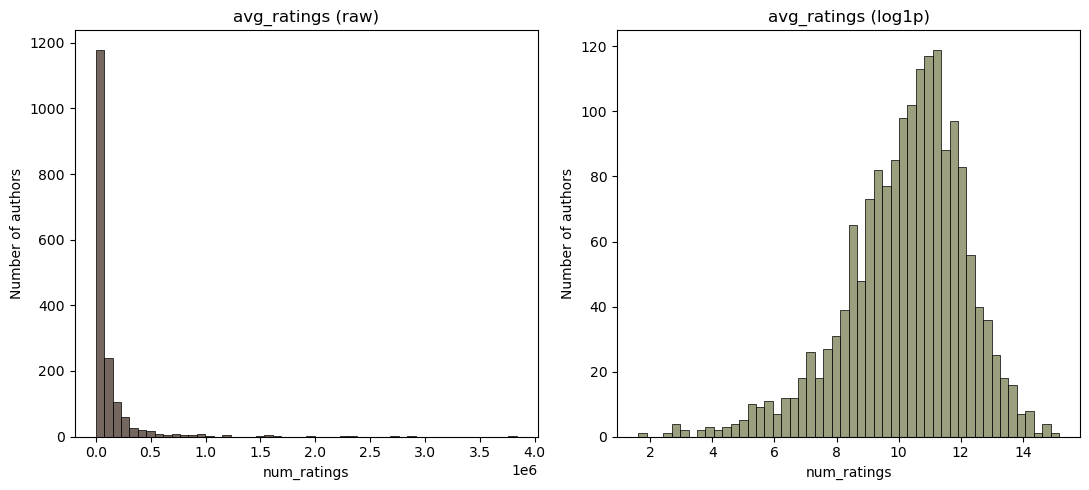

In [735]:
fig, axes = plt.subplots(1,2, figsize=(11,5))
axes = axes.flatten()

sns.histplot(author_stats, bins=50, color=dark_academia[4], ax=axes[0])
axes[0].set_title("avg_ratings (raw)")
axes[0].set_ylabel("Number of authors")

sns.histplot(np.log1p(author_stats), bins=50, color=dark_academia[2], ax=axes[1])
axes[1].set_title("avg_ratings (log1p)")
axes[1].set_ylabel("Number of authors")
plt.tight_layout()
plt.show()

For each book, I take the average num_ratings of the author's other books in the dataset (so that a book's own rating does not influence its score). The average num ratigns is log transformed because it is heavily skewed -> convert it to a percentile rank and set it on a scale of 1-10 so the score shows how "popular" relative to other authors

In [736]:
grp = df_goodreads.groupby("clean_author")["num_ratings"]
n_other = grp.transform("count") - 1 #for each book-> how many books the author has in the dataset (including the book itself, hence subtracting 1)
other_avg = (grp.transform("sum") - df_goodreads["num_ratings"]) / n_other.replace(0, np.nan)

Most of the authors have only 1 book, so there are no other books to avg to make the score. Filling in with the median treats them as the norm/typical instead of falsely labelling them the least popular

In [737]:
engagement = np.log1p(other_avg)
popularity = 1+9 * engagement.rank(pct=True)
df_goodreads["author_popularity"] = popularity.fillna(popularity.median()) #authors with one book get median
df_goodreads["single_book_author"] = (n_other == 0).astype(int) #0 = no other book

The median is a placeholder/proxy and not a reflecion of real popularity. The "single_book_author" flag shows that the author has no other books in the dataset (1 = no other books, 0 = has more than one book) -> the model can learn separately how much unknown authors matter and the popularity score only caries real information where it was actually computed/

In [738]:
df_goodreads[["author", "title", "author_popularity", "single_book_author"]].head()

,author,title,author_popularity,single_book_author
0,Jill Barklem,Summer Story,1.100239,0
1,Ruth Rendell,The Lake of Darkness,1.325776,0
2,Frederik Pohl,Beyond the Blue Event Horizon,5.501790,1
3,Ellis Peters,St. Peter's Fair,1.766110,0
4,Dick Francis,Twice Shy,1.737470,0


In [739]:
df_goodreads["author_popularity"].describe()

count    3590.000000
mean        5.501790
std         2.174442
min         1.003580
25%         4.215692
50%         5.501790
75%         6.787888
max        10.000000
Name: author_popularity, dtype: float64

Most of the authors have only 1 book, so there are no other books to avg to make the score. Filling in with the median treats them as the norm/typical instead of falsely labelling them the least popular

---
# 1. Exploratory Data Analysis (Final Dataset)
5 features... if i were to add reviews/ratings it would be like 7 but that would change the business scenario\
The other goodreads fields like want_to_read could be used idk, assuming they published the book, whichwould cover the scenario saying "their books". If that is the case, i would say the ML is not all that useful. What do they want with that prediction -> stocking?

## 1.1 Univariate Analysis

### 1.1.1 Target Class Distribution
Majority of the dataset is bestsellers. The class imbalance is not severe: 53% best sellers. It is often said that "every book is a new york times best seller", I suppose that shows in this dataset too

In [740]:
bestselling_colours = [desert_luxe[2], desert_luxe[1]]

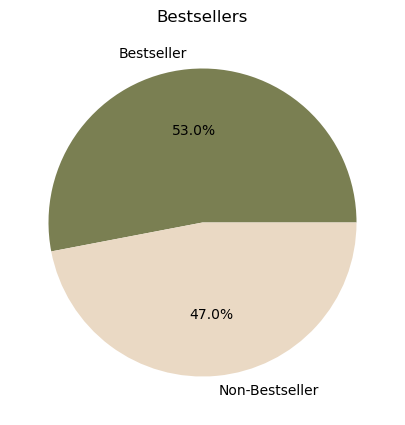

In [741]:
# BESTSELLER DISTRIBUTION pie chart
counts = df_goodreads["bestseller"].value_counts()
fig = plt.figure(figsize=(8,5))
plt.pie(counts.values, labels=["Bestseller", "Non-Bestseller"], autopct="%1.1f%%",  colors=bestselling_colours, wedgeprops={"linewidth":0})
plt.title("Bestsellers")
plt.show()

### 1.1.2 Feature Distributions

In [742]:
features = df_goodreads[["num_pages", "price", "clean_format", "is_fiction", "author_popularity", "single_book_author"]].columns

C:\Users\tshia\AppData\Local\Temp\ipykernel_25948\3725062232.py:3: UserWarning: The palette list has more values (5) than needed (2), which may not be intended.
  sns.countplot(data=df_goodreads, x="is_fiction", ax=axes[0], palette=dark_academia, hue="is_fiction", legend=False)
C:\Users\tshia\AppData\Local\Temp\ipykernel_25948\3725062232.py:6: UserWarning: The palette list has more values (5) than needed (3), which may not be intended.
  sns.countplot(data=df_goodreads, x="clean_format", ax=axes[1], palette=dark_academia, hue="clean_format", legend=False)


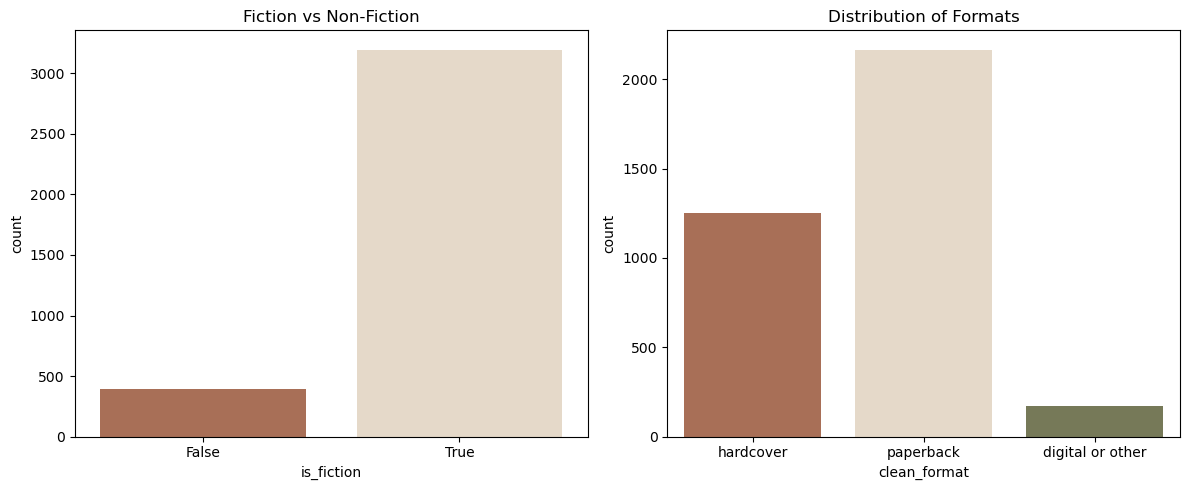

In [746]:
fig, axes = plt.subplots(1,2, figsize=(12, 5))
axes = axes.flatten()
sns.countplot(data=df_goodreads, x="is_fiction", ax=axes[0], palette=dark_academia, hue="is_fiction", legend=False)
axes[0].set_title(f"Fiction vs Non-Fiction")

sns.countplot(data=df_goodreads, x="clean_format", ax=axes[1], palette=dark_academia, hue="clean_format", legend=False)
axes[1].set_title(f"Distribution of Formats")

plt.tight_layout()
plt.show()

## Genre Distribution
Majority of the dataset is made up of fiction book, particularly, fantasy and romance. Followed by historical (mostly hisotrical fiction) and myserty/thriller

### Encode Genre with MLB

In [747]:
# build list of genres
df_goodreads["broad_genres"] = df_goodreads["genre_list"].apply(
    lambda tags: [gnr for gnr, pattern in genre_patterns.items()
                 if any(re.search(pattern, t) for t in tags)]
)
# encode
mlb = MultiLabelBinarizer()
encoded_genre = mlb.fit_transform(df_goodreads["broad_genres"])

genre_df = pd.DataFrame(
    encoded_genre, columns=["genre_" + gnr for gnr in mlb.classes_],
    index=df_goodreads.index
)

df_goodreads = pd.concat([df_goodreads, genre_df], axis=1)
genre_cols = list(genre_df.columns)
print(df_goodreads[genre_cols].sum().sort_values())

genre_spirituality            55
genre_science                 65
genre_graphic_novels          73
genre_self_help_business      94
genre_society                250
genre_children               283
genre_humor                  296
genre_science_fiction        581
genre_horror_paranormal      600
genre_young_adult            912
genre_mystery_thriller       927
genre_historical             996
genre_romance               1159
genre_fantasy               1428
dtype: int64


In [748]:
# GENRE barchart/countplot
genre_cols = [gc for gc in df_goodreads if gc.startswith("genre_") and gc != "genre_list"]
genre_counts = (df_goodreads[genre_cols].sum().rename(lambda gc: gc.replace("genre_", "").replace("_", "")).sort_values())

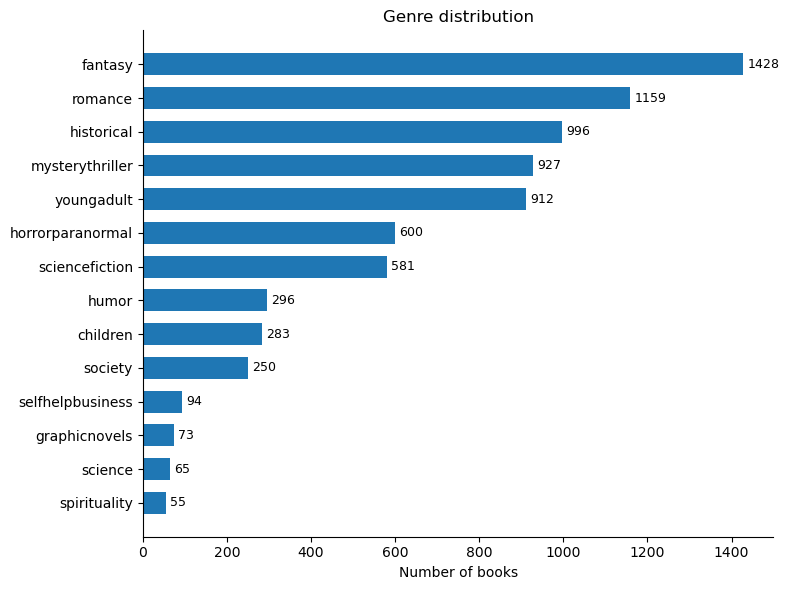

In [749]:
fig, axes = plt.subplots(figsize=(8,6))
bars = axes.barh(genre_counts.index, genre_counts.values, height=0.65)
axes.bar_label(bars, padding=3, fontsize=9)
axes.set_title("Genre distribution")
axes.set_xlabel("Number of books")
axes.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

### Numeric Feature Distribution
Pages is skewed to the right


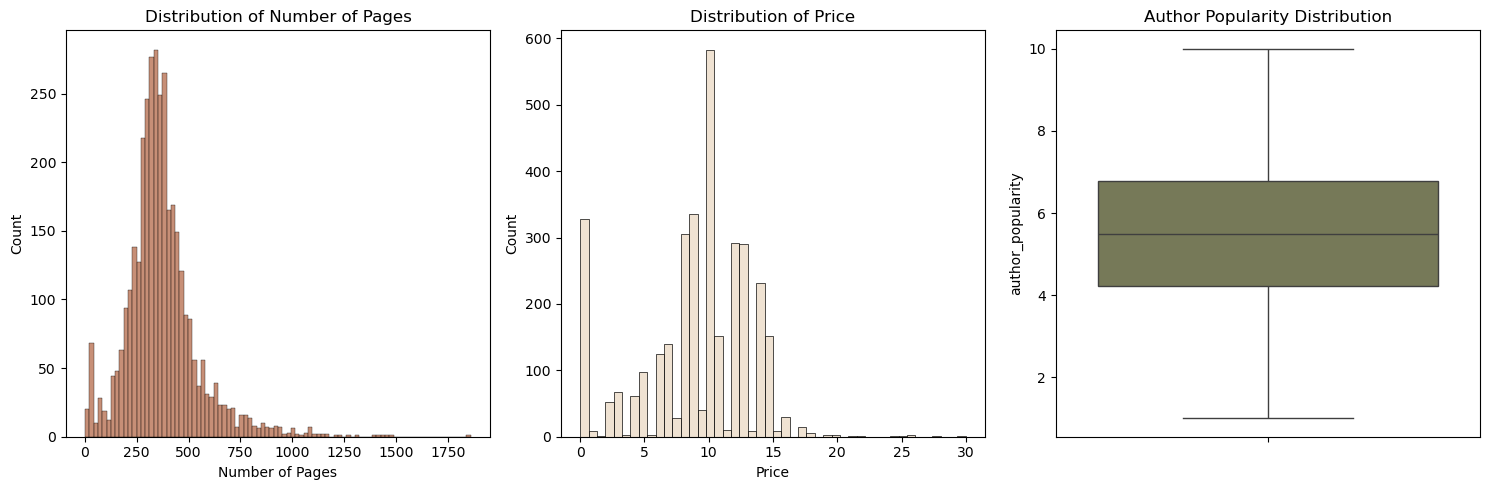

In [750]:
fig, axes = plt.subplots(1,3, figsize=(15, 5))
sns.histplot(data=df_goodreads, x="num_pages", ax=axes[0], color=dark_academia[0])
axes[0].set_title("Distribution of Number of Pages")
axes[0].set_xlabel("Number of Pages")

sns.histplot(data=df_goodreads, x="price", ax=axes[1], color=dark_academia[1])
axes[1].set_title("Distribution of Price")
axes[1].set_xlabel("Price")

sns.boxplot(data=df_goodreads, y="author_popularity", ax=axes[2], orient="v", color=dark_academia[2])
axes[2].set_title("Author Popularity Distribution")

plt.tight_layout()
plt.show()

In [751]:
num_features = ["num_pages", "price"]

In [752]:
skew_summary = pd.DataFrame({
    "Feature": num_features, 
    "Skewness": [skew(df_goodreads[col].dropna()) for col in num_features]
})

In [753]:
# https://www.geeksforgeeks.org/python/pandas-cut-method-in-python/
# (positive = right skew | negative = left skew | 0 = symmetric)
labels = ["Heavily Left Skewed", "Moderately Left Skewed", "Approximately Symmetric",
         "Moderately Right Skewed", "Heavily Right Skewed"]
bins = [-np.inf, -1, -0.5, 0.5, 1, np.inf]

skew_summary["Interpretation"] = pd.cut(
    skew_summary["Skewness"], bins=bins, labels=labels)
skew_summary.sort_values(by="Skewness", key=abs, ascending=False)

,Feature,Skewness,Interpretation
0,num_pages,1.540403,Heavily Right Skewed
1,price,-0.515737,Moderately Left Skewed


In [754]:
df_goodreads.columns

Index(['isbn', 'title', 'series_title', 'author', 'num_pages', 'format',
       'genres', 'rating_score', 'num_ratings', 'price', 'clean_author',
       'clean_title', 'bestseller', 'clean_format', 'genre_list', 'is_fiction',
       'author_popularity', 'single_book_author', 'broad_genres',
       'genre_children', 'genre_fantasy', 'genre_graphic_novels',
       'genre_historical', 'genre_horror_paranormal', 'genre_humor',
       'genre_mystery_thriller', 'genre_romance', 'genre_science',
       'genre_science_fiction', 'genre_self_help_business', 'genre_society',
       'genre_spirituality', 'genre_young_adult'],
      dtype='object')

## Bivariate Analysis

C:\Users\tshia\AppData\Local\Temp\ipykernel_25948\2135187117.py:7: UserWarning: The palette list has more values (5) than needed (2), which may not be intended.
  sns.barplot(data=df_goodreads, x="bestseller", y=feature, hue="bestseller", legend=False, ax=axes[i], palette=dark_academia)
C:\Users\tshia\AppData\Local\Temp\ipykernel_25948\2135187117.py:7: UserWarning: The palette list has more values (5) than needed (2), which may not be intended.
  sns.barplot(data=df_goodreads, x="bestseller", y=feature, hue="bestseller", legend=False, ax=axes[i], palette=dark_academia)


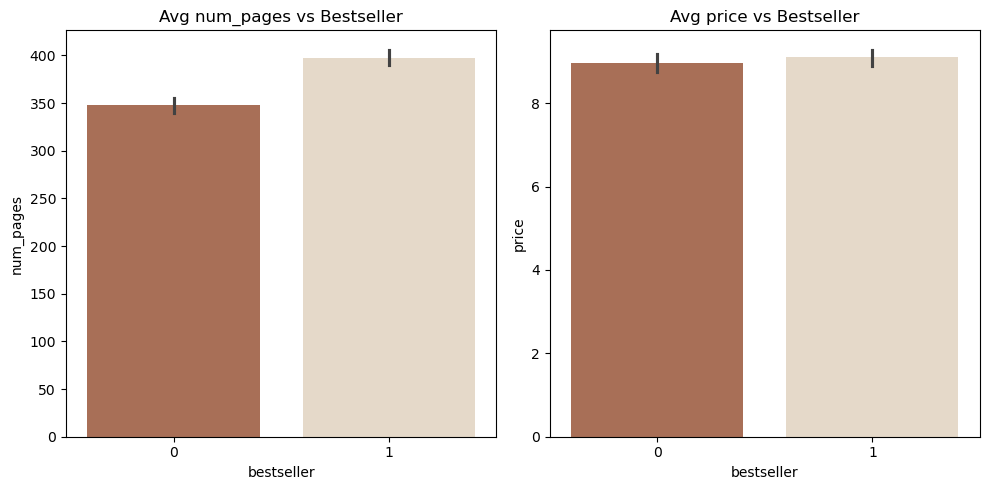

In [769]:
format_b_rate = (df_goodreads.groupby(df_goodreads["clean_format"], observed=True)["bestseller"].mean().reset_index())

fig, axes = plt.subplots(1,2, figsize=(10,5))
axes = axes.flatten()

for i, feature in enumerate(num_features):
    sns.barplot(data=df_goodreads, x="bestseller", y=feature, hue="bestseller", legend=False, ax=axes[i], palette=dark_academia)
    axes[i].set_title(f"Avg {feature} vs Bestseller")

plt.tight_layout()
plt.show()

In [ ]:
df_goodreads["is_fiction"].value_counts()

In [ ]:
format_b_rate = (df_goodreads.groupby(df_goodreads["clean_format"], observed=True)["bestseller"].mean().reset_index())
format_b_rate["bestseller"] *=100
format_b_rate

In [ ]:
sns.barplot(data=format_b_rate, y="bestseller", x="clean_format", hue="bestseller", legend=False) # bestseller rate among formats
plt.title("Bestselling Formats")
plt.ylabel("Average Number of Bestsellers")
plt.xlabel("Book Format")
plt.show() # which format onhas the most bestsellers.. there are more fiction than nonfiction anyway 

## Multivariate
Paperback and hard over are very strongly correlated -> 0.9

In [ ]:
from matplotlib.colors import LinearSegmentedColormap
# Features to compare: the target, numeric columns, 0/1 flags and one-hot format
format_dummies = pd.get_dummies(df_goodreads["clean_format"], prefix="format").astype(int)
features = pd.concat([df_goodreads[["bestseller", "is_fiction", "num_pages", "price"] + genre_cols],
                      format_dummies], axis=1)

# Spearman rather than Pearson: price and num_pages are skewed, and most columns are 0/1
corr = features.corr(method="spearman")
corr.columns = corr.columns.str.replace("genre_", "")      # shorter labels
corr.index = corr.index.str.replace("genre_", "")
            # hide the duplicate upper half
cmap = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f2f2f2", "#eb6834"])  # blue - grey - orange

plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap=cmap, vmin=-1, vmax=1, center=0,
            annot=True, fmt=".2f", annot_kws={"size": 6},
            linewidths=0.5, cbar_kws={"shrink": 0.7})
plt.title("Spearman correlation between features and bestseller", loc="left")
plt.tight_layout(); plt.show()

Hardcover and paperback are very highly correlated with each other, but they are dummies of the same feature

# Preprocessing

## Encode Format, Log transform 

In [ ]:
# encode format
ohe = OneHotEncoder(drop="first", sparse_output=False, dtype=int)

encoded = ohe.fit_transform(df_goodreads[["clean_format"]])
encoded_data = pd.DataFrame(
    encoded, columns=ohe.get_feature_names_out(["clean_format"]), index=df_goodreads.index,
)
df_goodreads = pd.concat([df_goodreads.drop(columns="clean_format"), encoded_data], axis=1)

In [ ]:
df = df_goodreads.copy()
df = df_goodreads.drop(columns=['isbn', 'title', 'series_title', 'author', 'clean_author',
       'clean_title', 'genre_list','format','genres', 'rating_score', 'num_ratings', 'broad_genres']).copy()

In [ ]:
df["is_fiction"] = df["is_fiction"].astype(int)

In [ ]:
df["num_pages"] = np.log1p(df["num_pages"])

## Test-Train Split

In [ ]:
X = df.drop("bestseller", axis=1)
y = df["bestseller"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

### Scaling and Imputing

In [ ]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
imputer = SimpleImputer(strategy="median")
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

---
# Building Logistic Regression
- https://towardsdatascience.com/logistic-regression-from-scratch-in-python-ec66603592e2/
- https://www.geeksforgeeks.org/machine-learning/implementation-of-logistic-regression-from-scratch-using-python/

check the googlecollab again

In [ ]:
class MyLogisticRegression:
    def __init__(self, learning_rate=0.01, iterations=100000, seed=42):
        self.lr = learning_rate
        self.iterations = iterations
        self.seed = seed
        self.weights = None
        self.bias = None
        self.all_costs = []

    def sigmoid(self, z):
        return 1/(1+np.exp(-z))

    def sigmoid_derivative(self, z):
        return self.sigmoid(z) * (1 - self.sigmoid(z))

    def cost(self, h, y):
        # cross entropy loss
        return -(y * np.log(h) + (1+y) * np.log(1-h))

    def fit(self, X, y):
        # train model with GD
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        m, n = X.shape

        np.random.seed(self.seed)
        self.weights = np.random.randn(n)
        self.bias = np.random.randn()
        self.all_costs = []

        for _ in range(self.iterations):
            random_number = np.random.randint(m)
            x = X[random_number]
            actual = y[random_number]

            # get weighted sum
            z = np.dot(x, self.weights) + self.bias
            predicted = np.clip(self.sigmoid(z), 1e-12, 1 - 1e-12) # keep log awy from0
            self.all_costs.append(self.cost(predicted, actual))

            #get deriv of cost fucnt - chainrule
            d_cost_predicted = -(actual/predicted) + (1 - actual)/ (1 - predicted)
            d_predicted_dz = self.sigmoid_derivative(z)

            dz_dw = x
            dz_db = 1

            dcost_dw = d_cost_predicted * d_predicted_dz * dz_dw
            dcost_db = d_cost_predicted * d_predicted_dz * dz_db

            #gradient descnt towards gmin
            self.weights = self.weights - self.lr * dcost_dw
            self.bias = self.bias - self.lr * dcost_db

    # probability of being a bestsellers
    def predict_proba(self, X):
        return self.sigmoid(np.dot(np.asarray(X, dtype=float), self.weights) + self.bias)

    # make predictions
    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

In [ ]:
myLr = MyLogisticRegression(learning_rate = 0.01, iterations=100000)

In [ ]:
myLr.fit(X_train, y_train)

In [ ]:
predictions = myLr.predict(X_test)

In [ ]:
#plot all_costs 
plt.plot(myLr.all_costs)
plt.title("Cost Function Over 100000 Iterations")
plt.xlabel("Iteration")
plt.ylabel("Cost Value (Error)")
plt.show()

#### Plot Cost

In [ ]:
print("My Logistic Regression Classification Report")
print(classification_report(y_test, predictions))

---
# Model Performamce Evaluation
use the usual accuracy, preci, recll, f1 score

Their business goal is to predict as accurately as possible, whether a book will sell really well. They want to know whether or not to invest in it, so it is important that it can reliably distinguish between bestsellers and non-best sellers. Model needs to be good at positive identification, while being precise -> consider PR tradeoff and therefore PR-AUC score and curve to demo how it does. Money is on the line, still tho, it is not a matter of extreme profit loss if a book does not hit the best seller list. Just because a book does not record particularly high sales in a given week, does not mean that it is not selling well -> maybe it will bring profit in slowly

### Classifcation Report
The model achieved an accuracy of 76%. It achieved a precision of 0.82, which means about 4 in 5 books the model’s flags are actually bestsellers. This metric is what matters most in deciding to invest in a book.\
It had a bestseller recall of 0.72, which means it finds about 72% of the real bestsellers but errs on the side of caution. It flags fewer books but is often correct when it does.\
The non-bestseller precision (0.72) and recall (0.82) showed that the two classes are treated similarly. Their F1-scores of 0.76 corroborate this. 

In [ ]:
print("My Logistic Regression Classification Report")
print(classification_report(y_test, predictions))

### Confusion Matrix

In [ ]:
ConfusionMatrixDisplay.from_predictions(y_test, predictions, cmap="flare")
plt.title("Confusion Matrix")

### ROC-AUC

In [ ]:
from sklearn.linear_model import LogisticRegression

In [ ]:
skLr = LogisticRegression()
skLr.fit(X_train, y_train)

In [ ]:
my_scores = myLr.predict_proba(X_test)
sklearn_scores = skLr.predict_proba(X_test)[:,1]

In [ ]:
plt.figure(figsize=(6, 5))

for name, scores, colour in [
    ("My logistic regression", my_scores, "#1e3a5f"),
    ("sklearn logistic regression", sklearn_scores, dark_academia[0])
]:
    fpr, tpr, _ = roc_curve(y_test, scores)
    auc = roc_auc_score(y_test, scores)
    plt.plot(fpr, tpr, color=colour, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], "--", color="#E7DDD0", label="Random guessing (AUC = 0.5)")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.title("ROC curve", loc="left")
plt.legend(loc="lower right")
plt.show()